# Simulasi Deep Neural Network (DNN) 2 Hidden Layers from Scratch
## Subkasus 1: Pemetaan Skalar $\mathbb{R}^3 \to \mathbb{R}^1$
### **Variasi 4 (Berdistribusi): Inisialisasi {M, Sigma, b Berbeda-beda}, Aktivasi ReLU**

Dokumen ini memuat implementasi *from scratch* komputasi matriks *forward pass* ($H^{(\ell)} = X^{(\ell-1)} W^{(\ell)} + \mathbf{1}_N \mathbf{b}^{(\ell)}$, $X^{(\ell)} = f(H^{(\ell)})$), evaluasi MSE *loss*, dan *backward pass* dengan konfigurasi berikut:

* **Sifat Bobot**: **Distribusi** (Reparameterization Trick: $W^{(\ell)} = M^{(\ell)} + \Sigma^{(\ell)} \odot Z^{(\ell)}$ dengan $Z^{(\ell)} \sim \mathcal{N}(0, I)$ matriks variabel acak normal baku)
* **Input Layer ($\ell = 0$)**: $n_0 = 3$ fitur
* **Hidden Layer 1 ($\ell = 1$)**: $n_1 = 4$ neuron, aktivasi ReLU
* **Hidden Layer 2 ($\ell = 2$)**: $n_2 = 6$ neuron, aktivasi ReLU
* **Output Layer ($\ell = 3$)**: $n_3 = 1$ neuron, aktivasi Linier
* **Banyak Data ($N$)**: $5$ sampel
* **Learning Rate ($\eta$)**: $0.5$
* **Total Iterasi**: $500$ iterasi
* **Random Seed**: $67$
* **Inisialisasi**: Parameter bernilai berbeda-beda / heterogen


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True, linewidth=120)

# 1. Kunci Random Seed
np.random.seed(67)

# 2. Matriks Data Input X in R^(5 x 3)
X = np.array([
    [0.1, 0.2, 0.3],
    [0.4, 0.1, 0.5],
    [0.2, 0.6, 0.1],
    [0.5, 0.3, 0.2],
    [0.3, 0.4, 0.4]
], dtype=np.float64)

# 3. Target Pemetaan R^3 -> R^1: y = 0.5*x1 - 0.3*x2 + 0.8*x3
Y = (0.5 * X[:, 0] - 0.3 * X[:, 1] + 0.8 * X[:, 2]).reshape(-1, 1)
N = X.shape[0]

# 4. Dimensi Jaringan
n0, n1, n2, n3 = 3, 4, 6, 1
lr = 0.5
num_epochs = 500

# 5. Fungsi Aktivasi Hidden Layer f(h) & Turunannya f'(h)
def activation(h):
    return np.maximum(0.0, h)

def activation_deriv(h):
    return (h > 0.0).astype(np.float64)

# 6. Inisialisasi Parameter Bobot dan Bias
# Matriks Rata-rata M, Simpangan Baku Sigma, dan Bias b bernilai berbeda-beda
M1 = np.array([
    [ 0.1, -0.2,  0.3,  0.1],
    [-0.1,  0.3, -0.1,  0.2],
    [ 0.2,  0.1, -0.2, -0.3]
], dtype=np.float64)
Sigma1 = np.array([
    [0.1, 0.2, 0.1, 0.2],
    [0.2, 0.1, 0.2, 0.1],
    [0.1, 0.2, 0.1, 0.2]
], dtype=np.float64)
b1 = np.array([[0.1, -0.1, 0.2, 0.0]], dtype=np.float64)

M2 = np.array([
    [ 0.2, -0.1,  0.3,  0.1, -0.2,  0.1],
    [-0.2,  0.2, -0.1,  0.3,  0.1, -0.1],
    [ 0.1, -0.3,  0.2, -0.1,  0.2,  0.3],
    [-0.1,  0.1, -0.2,  0.2, -0.1,  0.2]
], dtype=np.float64)
Sigma2 = np.array([
    [0.1, 0.2, 0.1, 0.2, 0.1, 0.2],
    [0.2, 0.1, 0.2, 0.1, 0.2, 0.1],
    [0.1, 0.2, 0.1, 0.2, 0.1, 0.2],
    [0.2, 0.1, 0.2, 0.1, 0.2, 0.1]
], dtype=np.float64)
b2 = np.array([[0.1, 0.0, -0.1, 0.2, -0.2, 0.1]], dtype=np.float64)

M3 = np.array([
    [ 0.3],
    [-0.2],
    [ 0.4],
    [-0.1],
    [ 0.2],
    [-0.3]
], dtype=np.float64)
Sigma3 = np.array([[0.1], [0.2], [0.1], [0.2], [0.1], [0.2]], dtype=np.float64)
b3 = np.array([[0.1]], dtype=np.float64)
print("Data Input X (5 x 3):\n", X)
print("\nData Target Y (5 x 1):\n", Y)


Data Input X (5 x 3):
 [[0.1 0.2 0.3]
 [0.4 0.1 0.5]
 [0.2 0.6 0.1]
 [0.5 0.3 0.2]
 [0.3 0.4 0.4]]

Data Target Y (5 x 1):
 [[0.23]
 [0.57]
 [0.  ]
 [0.32]
 [0.35]]


In [2]:
# Loop Pelatihan (500 Iterasi)
history = []
milestones = [1, 2, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500]
predictions_history = {}

for epoch in range(1, num_epochs + 1):
    # --- REPARAMETERIZATION TRICK & FORWARD PASS (BERDISTRIBUSI) ---
    # Z^(l) ~ N(0, I) adalah matriks variabel acak normal baku
    Z1 = np.random.randn(n0, n1)
    W1 = M1 + Sigma1 * Z1
    H1 = X @ W1 + b1
    X1 = activation(H1)
    
    Z2 = np.random.randn(n1, n2)
    W2 = M2 + Sigma2 * Z2
    H2 = X1 @ W2 + b2
    X2 = activation(H2)
    
    Z3 = np.random.randn(n2, n3)
    W3 = M3 + Sigma3 * Z3
    H3 = X2 @ W3 + b3
    Y_hat = H3
    
    # Evaluasi Loss: MSE = 1/(2N) * sum((Y - Y_hat)^2)
    loss = (0.5 / N) * np.sum((Y - Y_hat) ** 2)
    history.append((epoch, loss, Y_hat.copy()))
    if epoch in milestones:
        predictions_history[epoch] = Y_hat.copy()
        
    # --- BACKWARD PASS (BERDISTRIBUSI) ---
    # Layer 3 (l = 3)
    dL_dH3 = (1.0 / N) * (Y_hat - Y)             # (N x 1)
    dL_dW3 = X2.T @ dL_dH3                       # (6 x 1)
    dL_db3 = np.ones((1, N)) @ dL_dH3            # (1 x 1)
    dL_dM3 = dL_dW3
    dL_dSigma3 = dL_dW3 * Z3
    
    # Layer 2 (l = 2, menggunakan dL_dH3 dan W3 dari layer l+1 = 3)
    dL_dX2 = dL_dH3 @ W3.T                       # (N x 6)
    dL_dH2 = dL_dX2 * activation_deriv(H2)       # (N x 6)
    dL_dW2 = X1.T @ dL_dH2                       # (4 x 6)
    dL_db2 = np.ones((1, N)) @ dL_dH2            # (1 x 6)
    dL_dM2 = dL_dW2
    dL_dSigma2 = dL_dW2 * Z2
    
    # Layer 1 (l = 1, menggunakan dL_dH2 dan W2 dari layer l+1 = 2)
    dL_dX1 = dL_dH2 @ W2.T                       # (N x 4)
    dL_dH1 = dL_dX1 * activation_deriv(H1)       # (N x 4)
    dL_dW1 = X.T @ dL_dH1                        # (3 x 4)
    dL_db1 = np.ones((1, N)) @ dL_dH1            # (1 x 4)
    dL_dM1 = dL_dW1
    dL_dSigma1 = dL_dW1 * Z1
    
    # --- UPDATE PARAMETER DISTRIBUSI & BIAS ---
    M3 -= lr * dL_dM3
    Sigma3 -= lr * dL_dSigma3
    b3 -= lr * dL_db3
    
    M2 -= lr * dL_dM2
    Sigma2 -= lr * dL_dSigma2
    b2 -= lr * dL_db2
    
    M1 -= lr * dL_dM1
    Sigma1 -= lr * dL_dSigma1
    b1 -= lr * dL_db1
    
    if epoch in [1, 2]:
        print(f"================ DETAIL ITERASI KE-{epoch} ================")
        print("Z^(1):\n", Z1, "\nW^(1):\n", W1)
        print("Z^(2):\n", Z2, "\nW^(2):\n", W2)
        print("Z^(3):", Z3.ravel(), "\nW^(3):", W3.ravel())
        print("H^(1):\n", H1, "\nX^(1):\n", X1)
        print("H^(2):\n", H2, "\nX^(2):\n", X2)
        print(f"Y_hat: {Y_hat.ravel()} | Loss: {loss:.6f}")
        print("dL/dH^(3):", dL_dH3.ravel(), "| dL/dM^(3):", dL_dM3.ravel(), "| dL/dSigma^(3):", dL_dSigma3.ravel(), "| dL/db^(3):", dL_db3.ravel())
        print("dL/dX^(2):\n", dL_dX2, "\ndL/dH^(2):\n", dL_dH2)
        print("dL/dM^(2):\n", dL_dM2, "\ndL/dSigma^(2):\n", dL_dSigma2, "\ndL/db^(2):", dL_db2.ravel())
        print("dL/dX^(1):\n", dL_dX1, "\ndL/dH^(1):\n", dL_dH1)
        print("dL/dM^(1):\n", dL_dM1, "\ndL/dSigma^(1):\n", dL_dSigma1, "\ndL/db^(1):", dL_db1.ravel())
        print("Updated M^(3):", M3.ravel(), "| Sigma^(3):", Sigma3.ravel(), "| b^(3):", b3.ravel())
        print("Updated M^(2):\n", M2, "\nUpdated Sigma^(2):\n", Sigma2, "\nUpdated b^(2):", b2.ravel())
        print("Updated M^(1):\n", M1, "\nUpdated Sigma^(1):\n", Sigma1, "\nUpdated b^(1):", b1.ravel(), "\n")

# Tampilkan Rangkuman Nilai Tiap Kelipatan 50 Iterasi
print(f"{'Iterasi':<8} | {'MSE Loss':<12} | {'Rata-rata Prediksi':<20} | {'Prediksi y_hat [1..5]'}")
print("-" * 75)
for ep in milestones:
    _, ep_loss, ep_pred = history[ep - 1]
    pred_str = ", ".join([f"{val[0]:.4f}" for val in ep_pred])
    print(f"{ep:<8} | {ep_loss:<12.6f} | {np.mean(ep_pred):<20.4f} | [{pred_str}]")


================ DETAIL ITERASI KE-1 ================
Z^(1):
 [[ 1.1285  0.1442 -1.1153  1.231 ]
 [-0.1547 -0.5984  0.349   1.2206]
 [-0.8287 -1.1111 -0.5243 -1.0934]] 
W^(1):
 [[ 0.2129 -0.1712  0.1885  0.3462]
 [-0.1309  0.2402 -0.0302  0.3221]
 [ 0.1171 -0.1222 -0.2524 -0.5187]]
Z^(2):
 [[-1.6353 -1.685   0.6923 -2.3886 -0.7544 -1.0532]
 [ 1.7835  0.4447  0.1186  0.5277 -1.6998 -1.1453]
 [-0.5844  0.9073  0.5345  0.0515  0.5821 -0.8083]
 [-0.0859  0.3117 -1.0321  0.9448 -0.8261 -1.063 ]] 
W^(2):
 [[ 0.0365 -0.437   0.3692 -0.3777 -0.2754 -0.1106]
 [ 0.1567  0.2445 -0.0763  0.3528 -0.24   -0.2145]
 [ 0.0416 -0.1185  0.2534 -0.0897  0.2582  0.1383]
 [-0.1172  0.1312 -0.4064  0.2945 -0.2652  0.0937]]
Z^(3): [ 0.6063 -0.207  -0.7565 -2.3861  0.8739 -0.1124] 
W^(3): [ 0.3606 -0.2414  0.3244 -0.5772  0.2874 -0.3225]
H^(1):
 [[ 0.1302 -0.1057  0.1371 -0.0566]
 [ 0.2306 -0.2056  0.1462 -0.0887]
 [ 0.0757 -0.0024  0.1943  0.2106]
 [ 0.1906 -0.138   0.2347  0.166 ]
 [ 0.1583 -0.1042  0.1435  

Iterasi  | MSE Loss     | Rata-rata Prediksi   | Prediksi y_hat [1..5]
---------------------------------------------------------------------------
1        | 0.050638     | 0.0160               | [0.0262, 0.0603, -0.0382, 0.0042, 0.0277]
2        | 0.018299     | 0.2243               | [0.2355, 0.2354, 0.2109, 0.2076, 0.2322]
50       | 0.018290     | 0.4053               | [0.3857, 0.4456, 0.3561, 0.4366, 0.4024]
100      | 0.002874     | 0.2894               | [0.2923, 0.4678, 0.0886, 0.3289, 0.2694]
150      | 0.001900     | 0.2983               | [0.2821, 0.4890, 0.0775, 0.3475, 0.2955]
200      | 0.002871     | 0.3599               | [0.3444, 0.6300, 0.0285, 0.4233, 0.3732]
250      | 0.001260     | 0.2548               | [0.2421, 0.5166, -0.0273, 0.2760, 0.2668]
300      | 0.001013     | 0.2579               | [0.2303, 0.5188, -0.0257, 0.2950, 0.2711]
350      | 0.000564     | 0.3165               | [0.2815, 0.5957, 0.0166, 0.3599, 0.3287]
400      | 0.000221     | 0.2977        

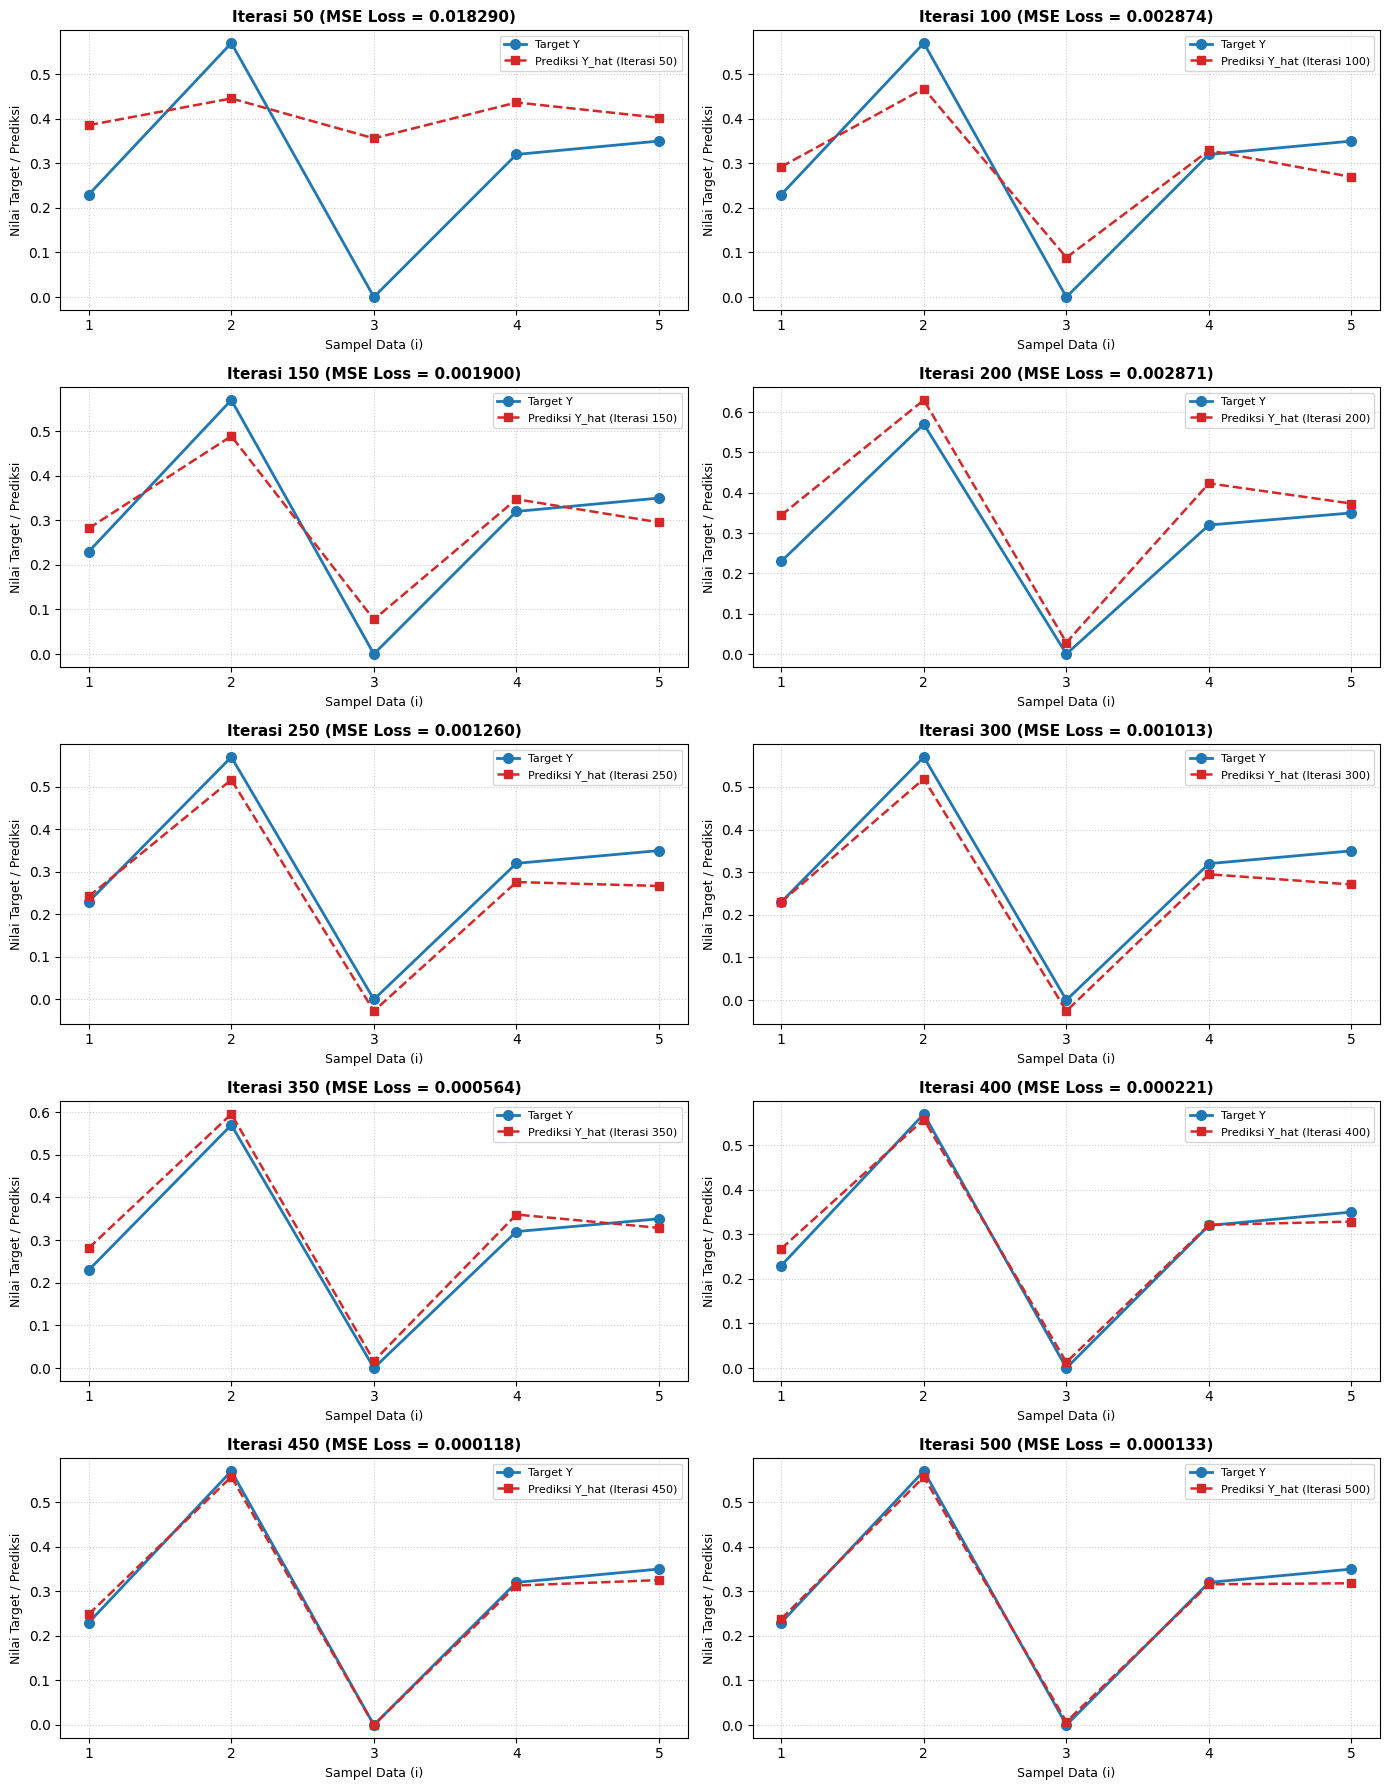

In [3]:
# Visualisasi Perbandingan Target vs Prediksi Setiap Kelipatan 50 Iterasi
plot_epochs = [50, 100, 150, 200, 250, 300, 350, 400, 450, 500]
samples = np.arange(1, N + 1)

fig, axes = plt.subplots(5, 2, figsize=(14, 18))
axes = axes.flatten()

for idx, ep in enumerate(plot_epochs):
    ax = axes[idx]
    y_pred_ep = predictions_history[ep].ravel()
    loss_ep = history[ep - 1][1]
    
    ax.plot(samples, Y.ravel(), 'o-', color='#1f77b4', linewidth=2, markersize=7, label='Target Y')
    ax.plot(samples, y_pred_ep, 's--', color='#d62728', linewidth=1.8, markersize=6, label=f'Prediksi Y_hat (Iterasi {ep})')
    
    ax.set_title(f'Iterasi {ep} (MSE Loss = {loss_ep:.6f})', fontsize=11, fontweight='bold')
    ax.set_xlabel('Sampel Data (i)', fontsize=9)
    ax.set_ylabel('Nilai Target / Prediksi', fontsize=9)
    ax.set_xticks(samples)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(fontsize=8, loc='best')

plt.tight_layout()
plt.show()


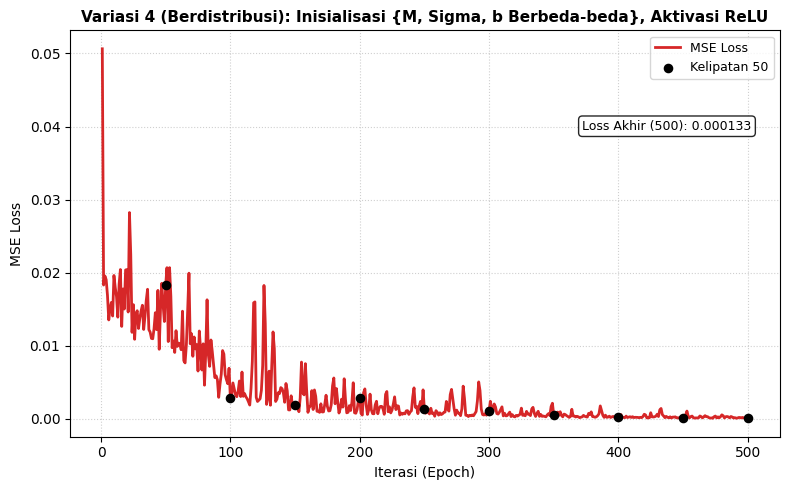

In [4]:
# Visualisasi Grafik Fungsi Loss (MSE Loss vs Iterasi 1 - 500)
epochs = np.array([h[0] for h in history])
losses = np.array([h[1] for h in history])

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(epochs, losses, color='#d62728', linewidth=2, label='MSE Loss')
milestone_epochs = [50, 100, 150, 200, 250, 300, 350, 400, 450, 500]
milestone_losses = [losses[ep - 1] for ep in milestone_epochs]
ax.scatter(milestone_epochs, milestone_losses, color='black', s=35, zorder=5, label='Kelipatan 50')

ax.set_title("Variasi 4 (Berdistribusi): Inisialisasi {M, Sigma, b Berbeda-beda}, Aktivasi ReLU", fontsize=11, fontweight='bold')
ax.set_xlabel('Iterasi (Epoch)', fontsize=10)
ax.set_ylabel('MSE Loss', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=9, loc='upper right')
ax.text(0.96, 0.78, f'Loss Akhir (500): {losses[-1]:.6f}', transform=ax.transAxes,
        fontsize=9, ha='right', va='top', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85))

plt.tight_layout()
plt.show()
